# Análise — idade de pico no 50m livre masculino (2010–2025)

Especificação principal:
1. remove linhas sem ano de nascimento
2. desempenho = tempo ÷ mediana do top 50 do ano (tempo relativo, ou seja menor = melhor)
3. pico = ano com menor tempo relativo de cada atleta
4. só atletas com ≥ 4 anos no top 50 (pelo menos 4 temporadas com tempos no top 50 mundial)
5. exclui atletas cujo pico caiu em 2010 ou 2025 (borda da janela)

Temporada = ano

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 8, "figure.dpi": 150})
LARGURA = 3.5

df = pd.read_csv("data/ranking_50livre_M_2010_2025.csv")
df = df[df["posicao"] <= 50]
df = df.dropna(subset=["ano_nascimento"])                         # filtro 1

mediana_ano = df.groupby("ano")["tempo_s"].median()
df["tempo_rel"] = df["tempo_s"] / df["ano"].map(mediana_ano)       # filtro 2
print(f"{len(df)} linhas, {df['atleta_id'].nunique()} atletas")
mediana_ano.round(2)

806 linhas, 253 atletas


ano
2010    22.34
2011    22.19
2012    22.04
2013    22.01
2014    22.10
2015    22.08
2016    22.02
2017    21.99
2018    22.00
2019    21.96
2020    22.10
2021    21.96
2022    21.91
2023    21.87
2024    21.81
2025    21.78
Name: tempo_s, dtype: float64

## Idade de pico

In [3]:
def idades_de_pico(dados, min_anos=4, tirar_borda=True, coluna="tempo_rel"):
    anos_por_atleta = dados.groupby("atleta_id")["ano"].nunique()
    dados = dados[dados["atleta_id"].isin(anos_por_atleta[anos_por_atleta >= min_anos].index)]   # filtro 4
    picos = dados.loc[dados.groupby("atleta_id")[coluna].idxmin()]                               # filtro 3
    if tirar_borda:
        picos = picos[~picos["ano"].isin([2010, 2025])]                                          # filtro 5
    return picos

def resumo(picos):
    i = picos["idade"]
    return {"n": len(i), "média": round(float(i.mean()), 1), "mediana": float(i.median()),
            "Q1": float(i.quantile(0.25)), "Q3": float(i.quantile(0.75))}

picos = idades_de_pico(df)
resumo(picos)

{'n': 65, 'média': 24.8, 'mediana': 24.0, 'Q1': 22.0, 'Q3': 27.0}

## Sensibilidade

In [4]:
variantes = {
    "Principal (≥4 anos)": idades_de_pico(df),
    "≥3 anos": idades_de_pico(df, min_anos=3),
    "≥5 anos": idades_de_pico(df, min_anos=5),
    "Sem filtro de borda": idades_de_pico(df, tirar_borda=False),
    "Sem 2020": idades_de_pico(df[df["ano"] != 2020]),
    "Sem splits": idades_de_pico(df[~df["split"]]),
    "Tempo absoluto": idades_de_pico(df, coluna="tempo_s"),
}
tabela = pd.DataFrame({nome: resumo(p) for nome, p in variantes.items()}).T
tabela

,n,média,mediana,Q1,Q3
Principal (≥4 anos),65.0,24.8,24.0,22.0,27.0
≥3 anos,93.0,24.3,24.0,22.0,26.0
≥5 anos,45.0,25.3,25.0,22.0,28.0
Sem filtro de borda,77.0,24.8,24.0,22.0,27.0
Sem 2020,59.0,24.8,24.0,22.0,27.5
Sem splits,65.0,24.8,24.0,22.0,27.0
Tempo absoluto,67.0,25.5,25.0,23.0,27.5


## Figura 1 — distribuição das idades de pico

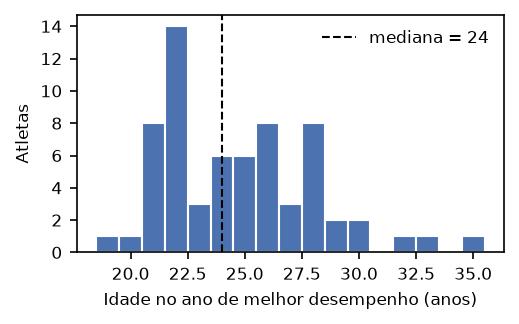

In [5]:
fig, ax = plt.subplots(figsize=(LARGURA, 2.2))
bins = range(int(picos["idade"].min()), int(picos["idade"].max()) + 2)
ax.hist(picos["idade"], bins=bins, align="left", color="#4C72B0", edgecolor="white")
ax.axvline(picos["idade"].median(), color="black", ls="--", lw=1, label=f"mediana = {picos['idade'].median():.0f}")
ax.set_xlabel("Idade no ano de melhor desempenho (anos)")
ax.set_ylabel("Atletas")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "hist_idade_pico.pdf")
plt.show()

## Figura 2 — desempenho relativo por idade (atletas da amostra principal)

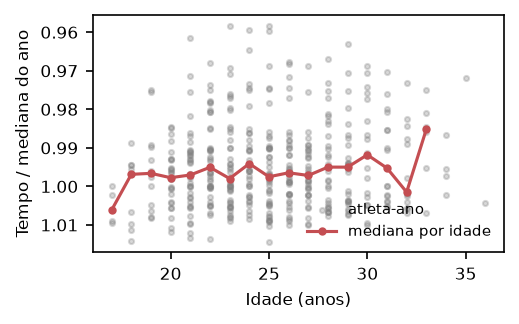

In [6]:
amostra = df[df["atleta_id"].isin(picos["atleta_id"])]
por_idade = amostra.groupby("idade")["tempo_rel"].agg(["median", "size"])
por_idade = por_idade[por_idade["size"] >= 5]   # idades com poucas observações ficam de fora

fig, ax = plt.subplots(figsize=(LARGURA, 2.2))
ax.scatter(amostra["idade"], amostra["tempo_rel"], s=6, alpha=0.3, color="gray", label="atleta-ano")
ax.plot(por_idade.index, por_idade["median"], "o-", color="#C44E52", ms=3, label="mediana por idade")
ax.invert_yaxis()   # mais rápido para cima
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Tempo / mediana do ano")
ax.legend(frameon=False, fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "desempenho_por_idade.pdf")
plt.show()